# Ok-k-mer

Use python310 conda environment

## Imports

In [1]:
import ok_k_mer

In [2]:
import importlib
importlib.reload(ok_k_mer)


<module 'ok_k_mer' from '/scratch4/blangme2/sjhwang/ok_k_mer/src/ok_k_mer.py'>

In [3]:
# import os
# import re
# import multiprocessing as mp
# from random import randint
# from random import sample
# from random import sample, seed as set_seed, randint
import numpy as np
import pandas as pd
from collections import Counter
from ete3 import Tree
from itertools import combinations, product
from scipy.stats import binom, geom, spearmanr, pearsonr

pd.options.display.max_rows = 40



In [4]:
# import matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mplpatches
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
%matplotlib inline

plt.rcParams['figure.dpi'] = 300
plt.rcParams['agg.path.chunksize'] = 10000

In [5]:
import warnings
warnings.filterwarnings("ignore")


In [6]:
# import plotnine

from plotnine import \
    ggplot, aes, theme, themes, element_blank, element_line, element_text, mapping, \
    geom_point, geom_jitter, geom_line, geom_bar, geom_boxplot, geom_violin, geom_histogram, \
    ggtitle, xlab, ylab, geom_vline, geom_hline, geom_abline, geom_col, geom_tile, \
    scale_x_discrete, scale_y_discrete, scale_x_continuous, scale_y_continuous, \
    scale_color_discrete, scale_fill_manual, scale_fill_hue, scale_fill_gradient, scale_color_manual, scale_color_hue, \
    guides, after_stat, \
    xlim, ylim
from plotnine.options import figure_size
from mizani.formatters import percent_format

# plotnine theme
def theme_tufte_func(base_size=19, base_family="sans", rotate=True, figure_size=None):
    ''' Plotnine plotting theme. '''
    thm = themes.theme_bw(base_size=base_size, base_family = base_family) + \
        theme(
            legend_background = element_blank(),
            legend_key = element_blank(),
            panel_background = element_blank(),
            panel_border = element_blank(),
            strip_background = element_blank(),
            plot_background = element_blank(),
            panel_grid = element_blank(),
            axis_line = element_line(colour = "black", size = 1),
            axis_text_y = element_text(colour = "black")
        )

    if rotate:
        thm += theme(axis_text_x=element_text(rotation=45, hjust=1))
    if figure_size is not None:
        thm += theme(figure_size=figure_size)
    return thm


## Process/Load data

In [9]:
# Load merged_dfs
#
#aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/dashingfull_genomes_ncbi'
#bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/dashingfull_genomes_ncbi'
#caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/dashingfull_genomes_ncbi'
#chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/dashingfull_genomes_ncbi'
#cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/dashingfull_genomes_ncbi'
#neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/dashingfull_genomes_ncbi'
#
#aquificota_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/p__Aquificota.nwk'
#bacillales_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/o__Bacillales_A.nwk'
#caldisericia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/c__Caldisericia.nwk'
#chlamydia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/o__Chlamydiales.nwk'
#cyano_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/o__Cyanobacteriales.nwk'
#neisseriaceae_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/f__Neisseriaceae.nwk'
#
# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = ok_k_mer.process_data(chlamydia_tree_path, chlamydia_dir_path)
# aquificota_tree_dict, aquificota_dashing_dfs, aquificota_merged_df = ok_k_mer.process_data(aquificota_tree_path, aquificota_dir_path)
# bacillales_tree_dict, bacillales_dashing_dfs, bacillales_merged_df = ok_k_mer.process_data(bacillales_tree_path, bacillales_dir_path)
# caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_merged_df = ok_k_mer.process_data(caldisericia_tree_path, caldisericia_dir_path)
# cyano_tree_dict, cyano_dashing_dfs, cyano_merged_df = ok_k_mer.process_data(cyano_tree_path, cyano_dir_path)
# neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_merged_df = ok_k_mer.process_data(neisseriaceae_tree_path, neisseriaceae_dir_path)
#
## Save each merged DataFrame to a CSV file
#aquificota_merged_df.to_csv('aquificota_merged_df.csv', index=False)
#bacillales_merged_df.to_csv('bacillales_merged_df.csv', index=False)
#caldisericia_merged_df.to_csv('caldisericia_merged_df.csv', index=False)
#chlamydia_merged_df.to_csv('chlamydia_merged_df.csv', index=False)
#cyano_merged_df.to_csv('cyano_merged_df.csv', index=False)
#neisseriaceae_merged_df.to_csv('neisseriaceae_merged_df.csv', index=False)

# Load each merged DataFrame
aquificota_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_merged_df.csv')
bacillales_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_merged_df.csv')
caldisericia_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_merged_df.csv')
chlamydia_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_merged_df.csv')
cyano_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_merged_df.csv')
neisseriaceae_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_merged_df.csv')

# Prepare a list of all available merged_dfs and their names
merged_df_datasets = [
    ("Aquificota", aquificota_merged_df),
    ("Bacillales", bacillales_merged_df),
    ("Caldisericia", caldisericia_merged_df),
    ("Chlamydia", chlamydia_merged_df),
    ("Cyano", cyano_merged_df),
    ("Neisseriaceae", neisseriaceae_merged_df),
]

In [10]:
# Load 1k data
#for name, merged_df in merged_df_datasets:
#    print(name)
#    M, (k, corr, pval) = ok_k_mer.initial_corr(merged_df, k_low=6, k_high=40)
#    np.save(f"{name}_1k_corr.npy", M)
#    print()

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_1k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_1k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_1k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor_1k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_1k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_slurm_tensor_1k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = np.abs(aquificota_grid)
bacillales_grid    = np.abs(bacillales_grid)
caldisericia_grid  = np.abs(caldisericia_grid)
chlamydia_grid     = np.abs(chlamydia_grid)
cyano_grid         = np.abs(cyano_grid)
neisseriaceae_grid = np.abs(neisseriaceae_grid)

datasets_1k = [
    ("Aquificota", aquificota_grid),
    ("Bacillales", bacillales_grid),
    ("Caldisericia", caldisericia_grid),
    ("Chlamydia", chlamydia_grid),
    ("Cyano", cyano_grid),
    ("Neisseriaceae", neisseriaceae_grid),
]

In [11]:
# Load 2k data

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_2k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_2k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_2k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_slurm_tensor_2k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_2k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neis_slurm_tensor_2k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = np.abs(aquificota_grid)
bacillales_grid    = np.abs(bacillales_grid)
caldisericia_grid  = np.abs(caldisericia_grid)
chlamydia_grid     = np.abs(chlamydia_grid)
cyano_grid         = np.abs(cyano_grid)
neisseriaceae_grid = np.abs(neisseriaceae_grid)

datasets_2k = [
    ("Aquificota", aquificota_grid),
    ("Bacillales", bacillales_grid),
    ("Caldisericia", caldisericia_grid),
    ("Chlamydia", chlamydia_grid),
    ("Cyano", cyano_grid),
    ("Neisseriaceae", neisseriaceae_grid),
]

In [12]:
# Load 3k data

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_3k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_3k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_3k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor_3k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_3k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_slurm_tensor_3k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = -1 * aquificota_grid
bacillales_grid    = -1 * bacillales_grid
caldisericia_grid  = -1 * caldisericia_grid
chlamydia_grid     = -1 * chlamydia_grid
cyano_grid         = -1 * cyano_grid
neisseriaceae_grid = -1 * neisseriaceae_grid

datasets_3k = [
    ("Aquificota", aquificota_grid, 20),
    ("Bacillales", bacillales_grid, 24),
    ("Caldisericia", caldisericia_grid, 20),
    ("Chlamydia", chlamydia_grid, 20),
    ("Cyano", cyano_grid, 20),
    ("Neisseriaceae", neisseriaceae_grid, 19),
]

In [13]:
# Load Dashing intersection cardinality data

aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/intersection_cardinality'
bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/intersection_cardinality'
caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/intersection_cardinality'
chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/intersection_cardinality'
cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/intersection_cardinality'
neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/intersection_cardinality'

aquificota_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/f__Neisseriaceae.nwk'

# aquificota_tree_dict, aquificota_dashing_dfs, aquificota_intersection_card_df = ok_k_mer.process_dashing_intersection_card(aquificota_tree_path, aquificota_dir_path)
# bacillales_tree_dict, bacillales_dashing_dfs, bacillales_intersection_card_df = ok_k_mer.process_dashing_intersection_card(bacillales_tree_path, bacillales_dir_path)
# caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_intersection_card_df = ok_k_mer.process_dashing_intersection_card(caldisericia_tree_path, caldisericia_dir_path)
# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_intersection_card_df = ok_k_mer.process_dashing_intersection_card(chlamydia_tree_path, chlamydia_dir_path)
# cyano_tree_dict, cyano_dashing_dfs, cyano_intersection_card_df = ok_k_mer.process_dashing_intersection_card(cyano_tree_path, cyano_dir_path)
# neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_intersection_card_df = ok_k_mer.process_dashing_intersection_card(neisseriaceae_tree_path, neisseriaceae_dir_path)

# LOAD csvs
aquificota_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_card_df.csv')
bacillales_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_card_df.csv')
caldisericia_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_card_df.csv')
chlamydia_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_card_df.csv')
cyano_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_card_df.csv')
neisseriaceae_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_card_df.csv')

# Prepare a list of all available merged_dfs and their names
intersection_cardinality_datasets = [
    ("Aquificota", aquificota_intersection_card_df),
    ("Bacillales", bacillales_intersection_card_df),
    ("Caldisericia", caldisericia_intersection_card_df),
    ("Chlamydia", chlamydia_intersection_card_df),
    ("Cyano", cyano_intersection_card_df),
    ("Neisseriaceae", neisseriaceae_intersection_card_df),
]

# Save each DataFrame as a CSV file named {name}_card.csv
# for name, df in intersection_cardinality_datasets:
    # df.to_csv(f"{name}_card.csv")


In [14]:
# Load KMC3 union cardinality data

aquificota_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/union_cardinality_kmc'
bacillales_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/union_cardinality_kmc'
caldisericia_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/union_cardinality_kmc'
chlamydia_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/union_cardinality_kmc'
cyano_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/union_cardinality_kmc'
neisseriaceae_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/union_cardinality_kmc'

aquificota_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/f__Neisseriaceae.nwk'

# aquificota_tree_dict, aquificota_dashing_dfs, aquificota_card_df = ok_k_mer.process_kmc_union_card(aquificota_tree_path, aquificota_dir_path)
# bacillales_tree_dict, bacillales_dashing_dfs, bacillales_card_df = ok_k_mer.process_kmc_union_card(bacillales_tree_path, bacillales_dir_path)
# caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_card_df = ok_k_mer.process_kmc_union_card(caldisericia_tree_path, caldisericia_dir_path)
# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_card_df = ok_k_mer.process_kmc_union_card(chlamydia_tree_path, chlamydia_dir_path)
# cyano_tree_dict, cyano_dashing_dfs, cyano_card_df = ok_k_mer.process_kmc_union_card(cyano_tree_path, cyano_dir_path)
# neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_card_df = ok_k_mer.process_kmc_union_card(neisseriaceae_tree_path, neisseriaceae_dir_path)

# Save each DataFrame as a CSV file named {name}_card.csv
# for name, df in union_cardinality_datasets:
    # df.to_csv(f"{name}_union_card.csv")

aquificota_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/union_cardinality_kmc/aquificota_union_card_df.csv')
bacillales_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/union_cardinality_kmc/bacillales_union_card_df.csv')
caldisericia_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/union_cardinality_kmc/caldisericia_union_card_df.csv')
chlamydia_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/union_cardinality_kmc/chlamydia_union_card_df.csv')
cyano_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/union_cardinality_kmc/cyano_union_card_df.csv')
neisseriaceae_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/union_cardinality_kmc/neisseriaceae_union_card_df.csv')

# Prepare a list of all available merged_dfs and their names
union_cardinality_datasets = [
    ("Aquificota", aquificota_union_card_df),
    ("Bacillales", bacillales_union_card_df),
    ("Caldisericia", caldisericia_union_card_df),
    ("Chlamydia", chlamydia_union_card_df),
    ("Cyano", cyano_union_card_df),
    ("Neisseriaceae", neisseriaceae_union_card_df),
]



## Make shared cmap

In [ ]:
# cmap_dict = build_cmap_dict(datasets_1k, datasets_2k, datasets_3k)
cmap_dict = ok_k_mer.build_cmap_dict(datasets_1k, datasets_2k, datasets_3k)


In [ ]:
## Optinally: visualize the cmap
#for name, (cmap, vmax) in cmap_dict.items():
#    print(name)
#    gradient = np.linspace(0, vmax, 1000).reshape(1, -1)
#    fig, ax = plt.subplots(figsize=(6, 1))
#    ax.imshow(gradient, aspect='auto', cmap=cmap)
#    ax.set_axis_off()
#    plt.title(f"Colormap: {name}")
#    plt.show()

## Grid search and heatmaps on (one to three) k-mers

### One k-mer

In [ ]:
# Run full grid search
for name, df in datasets_1k:
    if name == 'Chlamydia':
        print(name)
        ok_k_mer.plot_1k_colorbar_corr(name, df, k_low=6, k_high=40, cmap_vmax=cmap_dict[name])
        print()


### Two k-mers


In [ ]:
# Run full grid search
for name, results_matrix in datasets_2k:
    if name == 'Chlamydia':
        print(name)
        results_matrix = np.abs(results_matrix)
        # results_matrix, min_val, k1_min, k2_min, w_min, min_val = ok_k_mer.run_full_grid_corr(merged_df, k_low=6, k_high=40, w_low=0.05)   # run grid search, now is a slurm script
        ok_k_mer.plot_2k_grid_joint_corr_weight(name, results_matrix, k_low=6, k_high=40, cmap_vmax=cmap_dict[name])
        # ok_k_mer.plot_2k_grid_corr(name, results_matrix, k_low=6, k_high=40, cmap_vmax=cmap_dict[name])
        # ok_k_mer.plot_2k_grid_weights(name, results_matrix, k_low=6, k_high=40, w_low=0, w_high=1, w_step=0.05)
        print()


### Three k-mers

In [ ]:
# Run across all datasets

s = 2 # s = 3
k_low = 6
k_high = 40

# Run 3-kmer grid search
for name, grid_df, k_best in datasets_3k:
    if name == 'Chlamydia':
        print(name, k_best)
        results = ok_k_mer.plot_3k_grid_corr(name, grid_df, k_best, s=s, k_low=k_low, k_high=k_high, cmap_vmax=cmap_dict[name])
        # results_grid_corr = ok_k_mer.plot_3k_grid_joint_corr_weight(name, grid_df, k_best, s=s, k_low=k_low, k_high=k_high, cmap_vmax=cmap_dict[name], w_low=0, w_high=1, w_step=0.10)
        print()


## Plot k-mer cardinality
f(G1, G2, k) = G1(k) U G2(k) / 4**k


In [13]:

# Prepare a list of all available merged_dfs and their names
union_cardinality_datasets = [
    ("Aquificota", aquificota_union_card_df),
    ("Bacillales", bacillales_union_card_df),
    ("Caldisericia", caldisericia_union_card_df),
    ("Chlamydia", chlamydia_union_card_df),
    ("Cyano", cyano_union_card_df),
    ("Neisseriaceae", neisseriaceae_union_card_df),
]



In [ ]:
# plot k-mer cardinalities
k_min = 5
k_max = 50

for name, df in union_cardinality_datasets:
    print(f"Plotting k-mer cardinality for {name}")
    ok_k_mer.plot_kmer_dashing_card(df, name, k_min=k_min, k_max=k_max)
    ok_k_mer.plot_kmer_dashing_card(df, name, k_min=k_min, k_max=k_max, log=True)
    print()


# def plot_kmer_dashing_card(merged_card_df, name, k_min=5, k_max=64, log=False):


In [ ]:
# Compile k-mer cardinality stats per dataset.
# Each resulting DataFrame has k-mer lengths as columns and these rows:
#   1st quantile (25%), 2nd quantile (50%), 3rd quantile (75%), 4th quantile (100%),
#   average, standard deviation, variance.
k_min = 5
k_max = 50

dataset_kmer_stats = {}

for name, df in union_cardinality_datasets:
    cols = [f"k{k}_cardinality" for k in range(k_min, k_max + 1) if f"k{k}_cardinality" in df.columns]
    sub = df[cols].apply(pd.to_numeric, errors="coerce")

    stats_df = pd.DataFrame(
        {
            "1st quantile":       sub.quantile(0.25),
            "2nd quantile":       sub.quantile(0.50),
            "3rd quantile":       sub.quantile(0.75),
            "4th quantile":       sub.quantile(1.00),
            "average":            sub.mean(),
            "standard deviation": sub.std(),
            "variance":           sub.var(),
        }
    ).T
    stats_df.columns = [int(c[1:].split("_")[0]) for c in cols]
    stats_df.columns.name = "k"

    dataset_kmer_stats[name] = stats_df
    print(name)
    print(stats_df)
    print()



In [ ]:
dataset_kmer_stats.keys()


In [ ]:
# Save each DataFrame in dataset_kmer_stats as a TSV file
# for name, stats_df in dataset_kmer_stats.items():
    # stats_df.to_csv(f"../data/kmer_stats/{name}_kmer_stats.tsv", sep="\t")

In [ ]:
# Plot a quantile summary per dataset.
# x-axis: k-mer length (columns of stats_df)
# y-axis: k-mer cardinality (log scale, since values span many orders of magnitude)
# Shaded band: inter-quartile range (Q1 -> Q3)
# Lines: Q2 (median), Q4 (max), and the mean

for name, stats_df in dataset_kmer_stats.items():
    ks = np.asarray(stats_df.columns, dtype=int)
    q1 = stats_df.loc["1st quantile"].to_numpy(dtype=float)
    q2 = stats_df.loc["2nd quantile"].to_numpy(dtype=float)
    q3 = stats_df.loc["3rd quantile"].to_numpy(dtype=float)
    q4 = stats_df.loc["4th quantile"].to_numpy(dtype=float)
    mean = stats_df.loc["average"].to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(max(8, len(ks) * 0.25), 5))

    ax.fill_between(ks, q1, q3, alpha=0.25, color="C0", label="IQR (Q1\u2013Q3)")
    ax.plot(ks, q4, color="C3", linestyle="--", linewidth=1.2, label="max (Q4)")
    ax.plot(ks, q2, color="C0", linewidth=1.8, label="median (Q2)")
    ax.plot(ks, mean, color="k", linestyle=":", linewidth=1.2, label="mean")

    ax.set_yscale("log")
    ax.set_xlabel("k-mer length")
    ax.set_ylabel("k-mer cardinality")
    ax.set_title(f"{name}: k-mer cardinality quantile summary")
    ax.set_xticks(ks)
    ax.tick_params(axis="x", rotation=90)
    ax.grid(True, which="both", linestyle=":", alpha=0.4)
    ax.legend(loc="best", frameon=False)

    plt.tight_layout()
    plt.show()


In [ ]:

# Plot a quantile summary for all datasets in the same plot.
# x-axis: k-mer length (columns of stats_df)
# y-axis: k-mer cardinality (log scale, since values span many orders of magnitude)
# For each dataset: shaded band = IQR (Q1–Q3), line = median; all use different colors

fig, ax = plt.subplots(figsize=(max(8, max(len(df.columns) for df in dataset_kmer_stats.values()) * 0.25), 5))
colors = plt.cm.get_cmap("tab10")
for idx, (name, stats_df) in enumerate(dataset_kmer_stats.items()):
    color = colors(idx % 10)
    ks = np.asarray(stats_df.columns, dtype=int)
    q1 = stats_df.loc["1st quantile"].to_numpy(dtype=float)
    q2 = stats_df.loc["2nd quantile"].to_numpy(dtype=float)
    q3 = stats_df.loc["3rd quantile"].to_numpy(dtype=float)
    ax.fill_between(ks, q1, q3, alpha=0.2, color=color, label=f"{name} IQR (Q1–Q3)")
    ax.plot(ks, q2, color=color, linewidth=1.8, label=f"{name} median (Q2)")

ax.set_yscale("log")
ax.set_xlabel("k-mer length")
ax.set_ylabel("k-mer cardinality")
ax.set_title("k-mer cardinality quantile summary across datasets")
all_ks = np.unique(np.concatenate([np.asarray(df.columns, dtype=int) for df in dataset_kmer_stats.values()]))
ax.set_xticks(all_ks)
ax.tick_params(axis="x", rotation=90)
ax.grid(True, which="both", linestyle=":", alpha=0.4)
ax.legend(loc="best", frameon=False, ncol=2)
plt.tight_layout()
plt.show()


In [ ]:
# Plot only the median for all datasets in the same plot.
# x-axis: k-mer length (columns of stats_df)
# y-axis: k-mer cardinality (log scale, since values span many orders of magnitude)

fig, ax = plt.subplots(figsize=(max(8, max(len(df.columns) for df in dataset_kmer_stats.values()) * 0.25), 5))
colors = plt.cm.get_cmap("tab10")
for idx, (name, stats_df) in enumerate(dataset_kmer_stats.items()):
    color = colors(idx % 10)
    ks = np.asarray(stats_df.columns, dtype=int)
    q2 = stats_df.loc["2nd quantile"].to_numpy(dtype=float)
    ax.plot(ks, q2, color=color, linewidth=1.8, label=f"{name} median (Q2)")

ax.set_yscale("log")
ax.set_xlabel("k-mer length")
ax.set_ylabel("k-mer cardinality")
ax.set_title("k-mer cardinality median summary across datasets")
all_ks = np.unique(np.concatenate([np.asarray(df.columns, dtype=int) for df in dataset_kmer_stats.values()]))
ax.set_xticks(all_ks)
ax.tick_params(axis="x", rotation=90)
ax.grid(True, which="both", linestyle=":", alpha=0.4)
ax.legend(loc="best", frameon=False, ncol=2)
plt.tight_layout()
plt.show()


In [ ]:
# Plot relative spread (CV = std / mean) and absolute std for all datasets.
# Top panel:    coefficient of variation = std / mean  (unitless, linear y-axis)
# Bottom panel: standard deviation                     (same units as cardinality, log y-axis)
# x-axis (shared): k-mer length

max_n_ks = max(len(df.columns) for df in dataset_kmer_stats.values())
fig, (ax_cv, ax_std) = plt.subplots(
    2, 1,
    figsize=(max(8, max_n_ks * 0.25), 8),
    sharex=True,
)

colors = plt.cm.get_cmap("tab10")
for idx, (name, stats_df) in enumerate(dataset_kmer_stats.items()):
    color = colors(idx % 10)
    ks = np.asarray(stats_df.columns, dtype=int)
    std = stats_df.loc["standard deviation"].to_numpy(dtype=float)
    mean = stats_df.loc["average"].to_numpy(dtype=float)

    with np.errstate(divide="ignore", invalid="ignore"):
        cv = np.where(mean > 0, std / mean, np.nan)

    ax_cv.plot(ks, cv, color=color, linewidth=1.8, marker="o", markersize=3, label=name)
    ax_std.plot(ks, std, color=color, linewidth=1.8, marker="o", markersize=3, label=name)

ax_cv.set_ylabel("CV = std / mean")
ax_cv.set_title("k-mer cardinality: relative spread (CV) and absolute std across datasets")
ax_cv.grid(True, which="both", linestyle=":", alpha=0.4)
ax_cv.legend(loc="best", frameon=False)

ax_std.set_yscale("log")
ax_std.set_xlabel("k-mer length")
ax_std.set_ylabel("standard deviation")
all_ks = np.unique(np.concatenate([np.asarray(df.columns, dtype=int) for df in dataset_kmer_stats.values()]))
ax_std.set_xticks(all_ks)
ax_std.tick_params(axis="x", rotation=90)
ax_std.grid(True, which="both", linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()


# Single-k recommendation from -log10 cardinality dynamics

Goal: recommend a single k-mer length per dataset using only the dynamics
(1st / 2nd derivative) of `-log10` normalized k-mer cardinality `C(k) / 4^k`, then compare to the
known single-best k from the full grid search.

`y(k) = -log10(C(k) / 4^k)` has three regimes:
- **saturated** (`k<=9`): `C(k) / 4^k ~= 1`, slope `~=0`
- **transition** (`k~=9-14`): slope ramps up, the 2nd derivative peaks (`k~=11-12`)
- **linear** (`k>=14`): slope is constant at `~=log10(4)=0.602`, because each
  genome's distinct k-mer count has stabilized and `C(k) / 4^k ~= G/(4**k/2)`

The known single-best k (19-24) lies *inside* the linear regime, a fixed offset
past its onset. So the raw elbow / constant-slope onset are good lower bounds but
undershoot; an onset + calibrated offset is the best derivative-only recommender.

Helpers live in `ok_k_mer_card_explore.py`.

In [14]:
import importlib
import ok_k_mer_card_explore as ce
importlib.reload(ce)

# Load all per-dataset cardinality stats TSVs from the current directory.
card_stats = ce.load_all_kmer_stats("../data/kmer_stats")
print("Loaded datasets:", list(card_stats.keys()))
print("Known best k:", ce.KNOWN_BEST_K)

Loaded datasets: ['Aquificota', 'Bacillales', 'Caldisericia', 'Chlamydia', 'Cyano', 'Neisseriaceae']
Known best k: {'Aquificota': 20, 'Bacillales': 24, 'Caldisericia': 20, 'Chlamydia': 20, 'Cyano': 20, 'Neisseriaceae': 19}


In [ ]:
# Per-dataset 3-panel dynamics: y, 1st derivative, 2nd derivative.
# The red line marks the known single-best k.
# transform: "neglog10" -> y = -log10(.);  "raw" -> plot the cardinality directly.
# dynamics_normalized: True -> normalized C(k) / 4^k (default);  False -> raw C(k).
# dynamics_transform = "neglog10"
# dynamics_transform = "raw"
# dynamics_normalized = True
# dynamics_normalized = False

# dynamics_transform = "neglog10"
# dynamics_normalized = True
# dynamics_normalized = False

for name, stats_df in card_stats.items():
    print(name)
    ## Raw cardinality
    #dynamics_normalized = False
    #dynamics_transform = "raw"
    #ce.plot_logcard_dynamics(name, stats_df, stat="average", smooth=True,
    #                         transform=dynamics_transform,
    #                         normalized=dynamics_normalized)
    #plt.show()
    ## Normalized cardinality
    #dynamics_normalized = False
    #dynamics_transform = "neglog10"
    #ce.plot_logcard_dynamics(name, stats_df, stat="average", smooth=True,
    #                         transform=dynamics_transform,
    #                         normalized=dynamics_normalized)
    #plt.show()
    ## Log transformed raw cardinality
    #dynamics_normalized = True
    #dynamics_transform = "raw"
    #ce.plot_logcard_dynamics(name, stats_df, stat="average", smooth=True,
    #                         transform=dynamics_transform,
    #                         normalized=dynamics_normalized)
    #plt.show()
    # Log transformed normalized cardinality
    dynamics_normalized = True
    dynamics_transform = "neglog10"
    ce.plot_logcard_dynamics(name, stats_df, stat="average", smooth=True,
                             transform=dynamics_transform,
                             normalized=dynamics_normalized)
    plt.show()
    print()




In [ ]:
# Compare every derivative-based single-k estimator against the known optimum.
#   elbow_d2max        : k at max 2nd derivative (transition elbow)
#   slope_onset        : k where slope first reaches 95% of log10(4) (linear-regime onset)
#   transition_end     : k where 2nd derivative returns to ~0 after its peak
#   onset_plus_offset  : slope_onset + a constant offset calibrated on these datasets
estimator_table = ce.build_estimator_table(card_stats, stat="average", frac=0.95)
print("Calibrated onset->optimum offset:", estimator_table.attrs["calibrated_offset"])
estimator_table

### Takeaway

On these 6 datasets the pure derivative signals undershoot the optimum:
- `elbow_d2max` (~11-12) and `slope_onset` (~14-15) sit well below the true
  best k (19-24), with mean absolute error ~9 and ~6 respectively.
- `transition_end` (~16-17) is closer (MAE ~4) but still low.
- `slope_onset + offset` (offset ~6) is the best derivative-only recommender
  (MAE ~1.5), but the offset is empirically calibrated, not derived.

Interpretation: `-log10` union-cardinality dynamics pin down the *onset of the
linear (unsaturated) regime* as a robust lower bound, but the union-cardinality
summary saturates (slope, CV all go constant) exactly where the optimum lives,
so it cannot locate the optimum on its own. Signals that keep varying past
`k~=14` are explored below.

### Complementary signals to explore

The union-cardinality dynamics saturate near the optimum. Below we scaffold
other signals that may locate the optimum more directly:
1. relative-spread dynamics across pairs (CV, log-IQR) and their derivatives
2. a theoretical model `C(k) / 4^k = min(1, G / (4**k / 2))` with fitted effective
   genome size `G`
3. overlaying the *actual* one-k Spearman correlation curve (from the grid
   search tensors) against the derivative features, to see where each feature
   lands relative to the true optimum

In [ ]:
# (1) Relative-spread dynamics across genome pairs.
# Unlike the mean, CV / log-IQR can keep evolving past the linear-regime onset.
for name, stats_df in card_stats.items():
    spread = ce.compute_spread_dynamics(stats_df)
    opt_k = ce.KNOWN_BEST_K.get(name)

    fig, (ax_cv, ax_iqr) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    ax_cv.plot(spread.index, spread["cv"], marker="o", ms=3, color="C0")
    ax_cv.set_ylabel("CV = std / mean")
    ax_iqr.plot(spread.index, spread["iqr_log"], marker="o", ms=3, color="C2")
    ax_iqr.set_ylabel("log-IQR  (-log10 Q1 minus -log10 Q3)")
    ax_iqr.set_xlabel("k-mer length")
    ax_iqr.set_xticks(spread.index)
    ax_iqr.set_xticklabels(spread.index, fontsize=7, rotation=90)
    for ax_i in (ax_cv, ax_iqr):
        if opt_k is not None:
            ax_i.axvline(opt_k, color="C3", lw=1.5, label=f"known best k={opt_k}")
        ax_i.grid(True, ls=":", alpha=0.4)
        ax_i.legend(loc="best", frameon=False, fontsize=8)
    ax_cv.set_title(f"{name}: relative-spread dynamics")
    fig.tight_layout()
    plt.show()

In [ ]:
# (2) Theoretical model C(k) / 4^k = min(1, G / (4**k / 2)); fit G from the linear tail.
rows = []
for name, stats_df in card_stats.items():
    G, slope, intercept = ce.fit_effective_genome_size(stats_df, k_fit_min=16)
    rows.append({"dataset": name, "effective_G": G,
                 "fit_slope": slope, "asymptote": ce.ASYMPTOTIC_SLOPE})
genome_size_table = pd.DataFrame(rows).set_index("dataset")
print(genome_size_table)

# Overlay observed vs theoretical -log10 C(k) / 4^k for one example dataset.
example = next(iter(card_stats))
stats_df = card_stats[example]
G, _, _ = ce.fit_effective_genome_size(stats_df, k_fit_min=16)
deriv = ce.compute_logcard_derivatives(stats_df)
k = deriv["k"]
plt.figure(figsize=(8, 4))
plt.plot(k, deriv["y"], marker="o", ms=3, label="observed -log10(C(k) / 4^k)")
plt.plot(k, -np.log10(ce.theoretical_card(k, G)), ls="--",
         label=f"theoretical (G={G:,.0f})")
plt.ylabel("-log10(C(k) / 4^k)")
plt.xlabel("k-mer length")
plt.title(f"{example}: observed vs theoretical cardinality")

# Plot every k tick on the x-axis
plt.xticks(k, labels=[str(kk) for kk in k], fontsize=7, rotation=90)

plt.legend(frameon=False)
plt.grid(True, ls=":", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
# (3) Overlay the ACTUAL one-k Spearman correlation curve (grid-search tensor)
# against the cardinality derivatives, to see where each feature lands.
# Requires `datasets_1k` to be loaded (see the 1k load cell above).
# deriv_method: "gradient" (np.gradient, central diff) or "diff" (np.diff,
#   forward diff: d1 at midpoints, d2 at interior integer k).
# deriv_transform: "neglog10" (d/dk of -log10(.)) or "raw" (d/dk of cardinality).
# deriv_normalized: True -> normalized C(k) / 4^k (default);  False -> raw C(k).
deriv_method = "gradient"
# deriv_normalized = True
deriv_normalized = False
# deriv_transform = "neglog10"
deriv_transform = "raw"

base = "C(k) / 4^k" if deriv_normalized else "C(k)"
metric = f"-log10({base})" if deriv_transform == "neglog10" else base

try:
    onek_by_name = {name: np.abs(grid) for name, grid in datasets_1k}
except NameError:
    onek_by_name = {}
    print("datasets_1k not in scope; run the 1k-load cell first to enable overlay.")

for name, stats_df in card_stats.items():
    if name not in onek_by_name:
        continue
    grid = onek_by_name[name]            # columns: [k, |corr|, pval]
    grid_k = grid[:, 0].astype(int)
    grid_corr = grid[:, 1].astype(float)
    best_k = int(grid_k[np.nanargmax(grid_corr)])

    deriv = ce.compute_logcard_derivatives(stats_df, method=deriv_method,
                                           transform=deriv_transform,
                                           normalized=deriv_normalized)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(grid_k, grid_corr, color="C3", marker="o", ms=3,
            label="|Spearman corr| (one k)")
    ax.axvline(best_k, color="C3", ls="-", lw=1, alpha=0.6,
               label=f"grid argmax k={best_k}")
    ax.set_xlabel("k-mer length"); ax.set_ylabel("|Spearman corr|")
    ax.set_xticks(grid_k)
    ax.set_xticklabels(grid_k, fontsize=7, rotation=90)

    ax2 = ax.twinx()
    ax2.plot(deriv["k_d1"], deriv["d1"], color="C0", ls="--",
             label=f"d1 ({metric}, {deriv_method})")
    ax2.plot(deriv["k_d2"], deriv["d2"], color="C2", ls=":",
             label=f"d2 ({metric}, {deriv_method})")
    ax2.set_ylabel(f"derivatives of {metric}")

    lines = ax.get_lines() + ax2.get_lines()
    ax.legend(lines, [ln.get_label() for ln in lines], loc="lower right",
              frameon=False, fontsize=8)
    ax.set_title(f"{name}: one-k correlation vs {metric} derivatives ({deriv_method})")
    ax.grid(True, ls=":", alpha=0.4)
    fig.tight_layout(); plt.show()


# Derivative-based k-mer selection (`ok_k_mer_selection`)

Select k-mer lengths from the 2nd derivative of `-log10(C(k) / 4^k)`: `k1` is
the transition elbow (argmax of the 2nd derivative), and we add the geometric
multiples `2*k1` and `3*k1`. Selected lengths are evaluated by evenly averaging
the per-pair distance ranks and correlating that average with the true tree
distance (Spearman's rho; the distance metric is similarity-like, so a more
negative correlation is stronger -- `abs_corr_*` gives the magnitude).

* **Global**: one `k1` per dataset, from the dataset-wide all-pairs `average`
  cardinality curve.
* **Pairwise**: each genome pair gets its own `k1` from its own cardinality
  curve, so pairs are evaluated at different (multiplied) k.

In [15]:
import importlib
import ok_k_mer_selection as sel
importlib.reload(sel)

# Reuses card_stats (cell ~52), union_cardinality_datasets (cell ~34) and
# merged_df_datasets (cell ~10) defined earlier in this notebook.

<module 'ok_k_mer_selection' from '/scratch4/blangme2/sjhwang/ok_k_mer/src/ok_k_mer_selection.py'>

In [ ]:
# Global scheme: one k1 (= 2nd-derivative elbow) per dataset, plus 2x and 3x.
global_results = sel.run_global_all(card_stats, merged_df_datasets)
global_results

In [ ]:
# Pairwise scheme: each genome pair selects its own k1 (and 2x / 3x).
pairwise_results = sel.run_pairwise_all(union_cardinality_datasets, merged_df_datasets)
pairwise_results

In [ ]:
# Side-by-side comparison of the two schemes (Spearman magnitudes).
comparison = pd.DataFrame({
    "global_ks_2kmer": global_results["ks_2kmer"],
    "global_ks_3kmer": global_results["ks_3kmer"],
    "global_2kmer": global_results["abs_corr_2kmer"],
    "global_3kmer": global_results["abs_corr_3kmer"],
    "pairwise_2kmer": pairwise_results["abs_corr_2kmer"],
    "pairwise_3kmer": pairwise_results["abs_corr_3kmer"],
})

comparison

# Stability based-k-mer selection

## Jaccard stability vs k

For each dataset in `merged_df_datasets`, plot the jaccard distance (mean across
pairs with a 25-75% IQR band) and the one-k Spearman correlation with tree
distance, against k. The red line marks the single-best k (argmax of |corr|) and
the shaded span marks the range of k whose correlation stays within `frac` of the
peak (i.e. where correlation is *stable*).

### Stability summary (frac = 0.99)

`stable_width` is the number of k whose one-k |corr| stays within 1% of the
per-dataset peak (the contiguous band around `best_k`). A wider band means the
k choice is more robust; a width of 1 means the peak is sharp/brittle.

| dataset | best_k | stable range | stable_width | max \|corr\| |
| --- | --- | --- | --- | --- |
| Aquificota | 20 | 20-22 | 3 | 0.69 |
| Bacillales | 24 | 21-26 | 6 | 0.70 |
| Caldisericia | 20 | 20-21 | 2 | 0.77 |
| Chlamydia | 20 | 20-20 | 1 | 0.42 |
| Cyano | 20 | 20-22 | 3 | 0.79 |
| Neisseriaceae | 19 | 17-24 | 8 | 0.90 |

Takeaways: all six datasets peak at k ~ 19-24, clustering tightly around k = 20.
Neisseriaceae has the broadest stable plateau (k 17-24) and the strongest peak
correlation, while Chlamydia is the sharpest (width 1) and weakest (|corr| ~ 0.42),
so its optimum is the least robust. The shared ~k=20 optimum suggests a single
k near 20 is a reasonable default across these clades.

In [ ]:
import importlib, ok_k_mer_stability_explore as se
importlib.reload(se)

stability_summary = se.plot_all_stability(merged_df_datasets, frac=0.99)

### No ground-truth selection: jaccard-curve elbow

Without the tree, select k purely from the shape of the jaccard mean vs k. The
curve decays from ~1 (saturation) to ~0; its 2nd derivative is most negative at
the saturation->decline onset, which we take as the elbow (`argmin` of d2). The
summary also reports `corr_best_k` (the ground-truth argmax of |corr|) so the
no-ground-truth elbow can be compared against the supervised optimum.

In [ ]:
importlib.reload(se)
# Ground-truth-free: elbow (argmin of 2nd derivative) of the raw jaccard mean.
jaccard_elbow_summary = se.plot_all_jaccard_derivatives(merged_df_datasets)
jaccard_elbow_summary

### Ground-truth-free k selection: 4 options compared

Four no-tree signals for picking a single k, all from the jaccard distance
columns alone:

1. **Discriminative spread** - k maximizing across-pair spread (`max_iqr` / `max_var`).
2. **Rank stability** - k whose pair ranking agrees most with its neighbour (`rank_stable`).
3. **Signal-to-noise** - k maximizing `mean/std` (`max_snr`) or `std/mean` (`max_cv`).
4. **Usable window** - bracket [onset elbow, floor knee], then take the spread argmax inside it (`window_spread`).

`corr_best_k` is the supervised optimum (argmax of |corr| with the tree); the
`abs_err_*` columns and the `MAE` row measure how close each unsupervised
estimator lands to it.

In [ ]:
importlib.reload(se)
unsupervised_summary = se.compare_unsupervised_estimators(merged_df_datasets)
unsupervised_summary

### Ground-truth-free estimator results

| dataset | onset_elbow | floor_knee | max_iqr | max_var | rank_stable | max_snr | max_cv | window | window_spread | corr_best_k |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Aquificota | 9 | 12 | 10 | 10 | 13 | 8 | 14 | 9-12 | 10 | 20 |
| Bacillales | 10 | 12 | 11 | 11 | 13 | 10 | 14 | 10-12 | 11 | 24 |
| Caldisericia | 9 | 12 | 10 | 10 | 13 | 8 | 13 | 9-12 | 10 | 20 |
| Chlamydia | 9 | 12 | 10 | 10 | 13 | 9 | 13 | 9-12 | 10 | 20 |
| Cyano | 10 | 13 | 11 | 11 | 14 | 9 | 15 | 10-13 | 11 | 20 |
| Neisseriaceae | 9 | 12 | 10 | 11 | 14 | 9 | 16 | 9-12 | 10 | 19 |

Takeaway: every jaccard-shape signal lands in k ~ 8-16, well below the
supervised optimum of k ~ 19-24, so all four options systematically
underestimate the best k. `max_cv` (k 13-16) and `rank_stable` (k 13-14) come
closest; `max_snr` and the onset elbow are the lowest. The offset is fairly
constant across clades, suggesting a calibrated `+offset` rule could recover
the supervised optimum.

## Union vs intersection cardinality

Two-panel plot per dataset: top is the raw (non-normalized) cardinality `C(k)`
(log y-axis), bottom is the normalized `C(k) / 4^k` using
`num_distinct_canonical_kmers`. The best single k is marked with a red dotted
vertical line.

In [ ]:
import importlib
import ok_k_mer_card_explore as ce
importlib.reload(ce)

for (name, union_df), (_, inter_df) in zip(union_cardinality_datasets,
                                           intersection_cardinality_datasets):
    ce.plot_union_intersection_card(name, union_df, inter_df, max_k=32)
    plt.show()

In [ ]:
import importlib
import ok_k_mer_card_explore as ce
importlib.reload(ce)

for (name, union_df), (_, inter_df) in zip(union_cardinality_datasets,
                                           intersection_cardinality_datasets):
    ce.plot_union_intersection_card(name, union_df, inter_df, max_k=32)
    plt.show()

# Plotting tree with k-mer pie chart

In [24]:
from ete3 import Tree, TreeStyle, TextFace, NodeStyle, faces
import ok_k_mer_tree_mask as tm
importlib.reload(tm)


<module 'ok_k_mer_tree_mask' from '/scratch4/blangme2/sjhwang/ok_k_mer/src/ok_k_mer_tree_mask.py'>

In [17]:
# Paths to the Newick trees for each dataset (same order as merged_df_datasets)
tree_datasets = [
    ("Aquificota",    "/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/p__Aquificota.nwk"),
    ("Bacillales",    "/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/o__Bacillales_A.nwk"),
    ("Caldisericia",  "/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/c__Caldisericia.nwk"),
    ("Chlamydia",     "/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/o__Chlamydiales.nwk"),
    ("Cyano",         "/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/o__Cyanobacteriales.nwk"),
    ("Neisseriaceae", "/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/f__Neisseriaceae.nwk"),
]


In [ ]:
## Plotting for slides:
#
#for (name, merged_df), (tree_name, tree_path) in zip(merged_df_datasets, tree_datasets):
#    # if name == "Caldisericia": # if name == "Chlamydia":
#    if name == "Cyano":
#        print(name)
#        # tm.plot_tree(tree_path, name=name)
#        tm.plot_dataset_tree(name, tree_path, merged_df=merged_df,
#                             annotate=True, k_low=6, k_high=40, w_step=0.05)
#        print()
#
#
#
## Cyano subtree: root k=7,18 w=0.05 corr=0.747 and descendants
#cyano_tree = tm.load_named_tree(tree_datasets[4][1])
#cyano_mdf = merged_df_datasets[4][1]
#cyano_node_info = tm.compute_node_annotations(
#    cyano_tree, cyano_mdf, k_low=6, k_high=40, w_step=0.05)
#cyano_subtree_root = tm.find_node_by_annotation(
#    cyano_node_info, k1=8, k2=18, w=0.05, corr=0.929)
#tm.plot_subtree_annotated(
#    cyano_tree, cyano_node_info, cyano_subtree_root, name='Cyano',
#    outpath='res/Cyano_subtree_node299_annotated.png', width=1200, scale=3000)

In [ ]:
## Plot each tree with no annotations
#for name, tree_path in tree_datasets:
#    print(name)
#    tm.plot_tree(tree_path, name=name)
#    print()

# Annotate each internal node with its best k-mer/tree-distance correlation
# and the two-k weighted average that achieves it.
for (name, merged_df), (tree_name, tree_path) in zip(merged_df_datasets, tree_datasets):
    print(name)
    tm.plot_dataset_tree(name, tree_path, merged_df=merged_df,
                         annotate=True, k_low=6, k_high=40)
    print()


## Masked-tree robustness

Mask a fraction of the genomes (leaves), then re-evaluate each internal
node's best k-mer recommendation using only the *un-masked* genomes under
that node. The full tree topology is kept and masked genomes are grayed out.

In [ ]:
## Re-plot each dataset's annotated tree after masking a fraction of genomes.
#mask_frac = 0.3
#for (name, merged_df), (tree_name, tree_path) in zip(merged_df_datasets, tree_datasets):
#    print(f"{name} (masking {int(mask_frac * 100)}% of genomes)")
#    tm.plot_masked_tree(name, tree_path, merged_df, frac=mask_frac, seed=0,
#                        k_low=6, k_high=40)
#    print()

## Global consistency vs masking fraction

Does masking x% of the genomes still yield a robust whole-tree k-mer
recommendation? For each fraction we mask several random subsets and
recompute the recommendation on the rest, comparing to the full-data
recommendation via four scores (mean +/- 1 std over runs):

- **match rate**: fraction of runs whose `k_eff` is within +/-1 k of full.
- **mean |dk_eff|**: average absolute deviation of `k_eff` from full.
- **correlation retention**: `|corr_masked| / |corr_full|`.
- **genome-pair ordering**: normalized Kendall-tau distance between the
  full and masked recommendations' pair orderings, plus the degradation of
  the masked ordering relative to the tree-distance truth.

In [19]:
# plotting for slides

mask_fracs = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

# new global consistency results, effective match:
global_consistency_results = {}
for (name, merged_df), (tree_name, tree_path) in zip(merged_df_datasets, tree_datasets):
    print(name)
    tree = tm.load_named_tree(tree_path)
    res = tm.global_effective_match_consistency(tree, merged_df, fracs=mask_fracs, n_runs=15, # from 10
                                k_low=6, k_high=40, seed=0)
    tm.save_global_effective_match_results(res, f"res/{name}_global_eff_match.pkl")
    global_consistency_results[name] = res
    tm.plot_global_effective_match_consistency(res, name)
    print()

# Replot without re-running simulation:
# res = tm.load_global_effective_match_results("res/Bacillales_global_eff_match.pkl")
# tm.plot_global_effective_match_consistency(res, "Bacillales")


Aquificota


KeyboardInterrupt: 

In [ ]:
# mask_fracs = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]    # og
mask_fracs = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

In [ ]:
# new global consistency results, effective match:

global_consistency_results = {}
for (name, merged_df), (tree_name, tree_path) in zip(merged_df_datasets, tree_datasets):
    print(name)
    tree = tm.load_named_tree(tree_path)
    res = tm.global_effective_match_consistency(tree, merged_df, fracs=mask_fracs, n_runs=15, # from 10
                                k_low=6, k_high=40, seed=0)
    tm.save_global_effective_match_results(res, f"res/{name}_global_eff_match.pkl")
    global_consistency_results[name] = res
    tm.plot_global_effective_match_consistency(res, name)
    print()

# Replot without re-running simulation:
# res = tm.load_global_effective_match_results("res/Bacillales_global_eff_match.pkl")
# tm.plot_global_effective_match_consistency(res, "Bacillales")

Aquificota
Bacillales
Caldisericia
Chlamydia
Cyano
Neisseriaceae


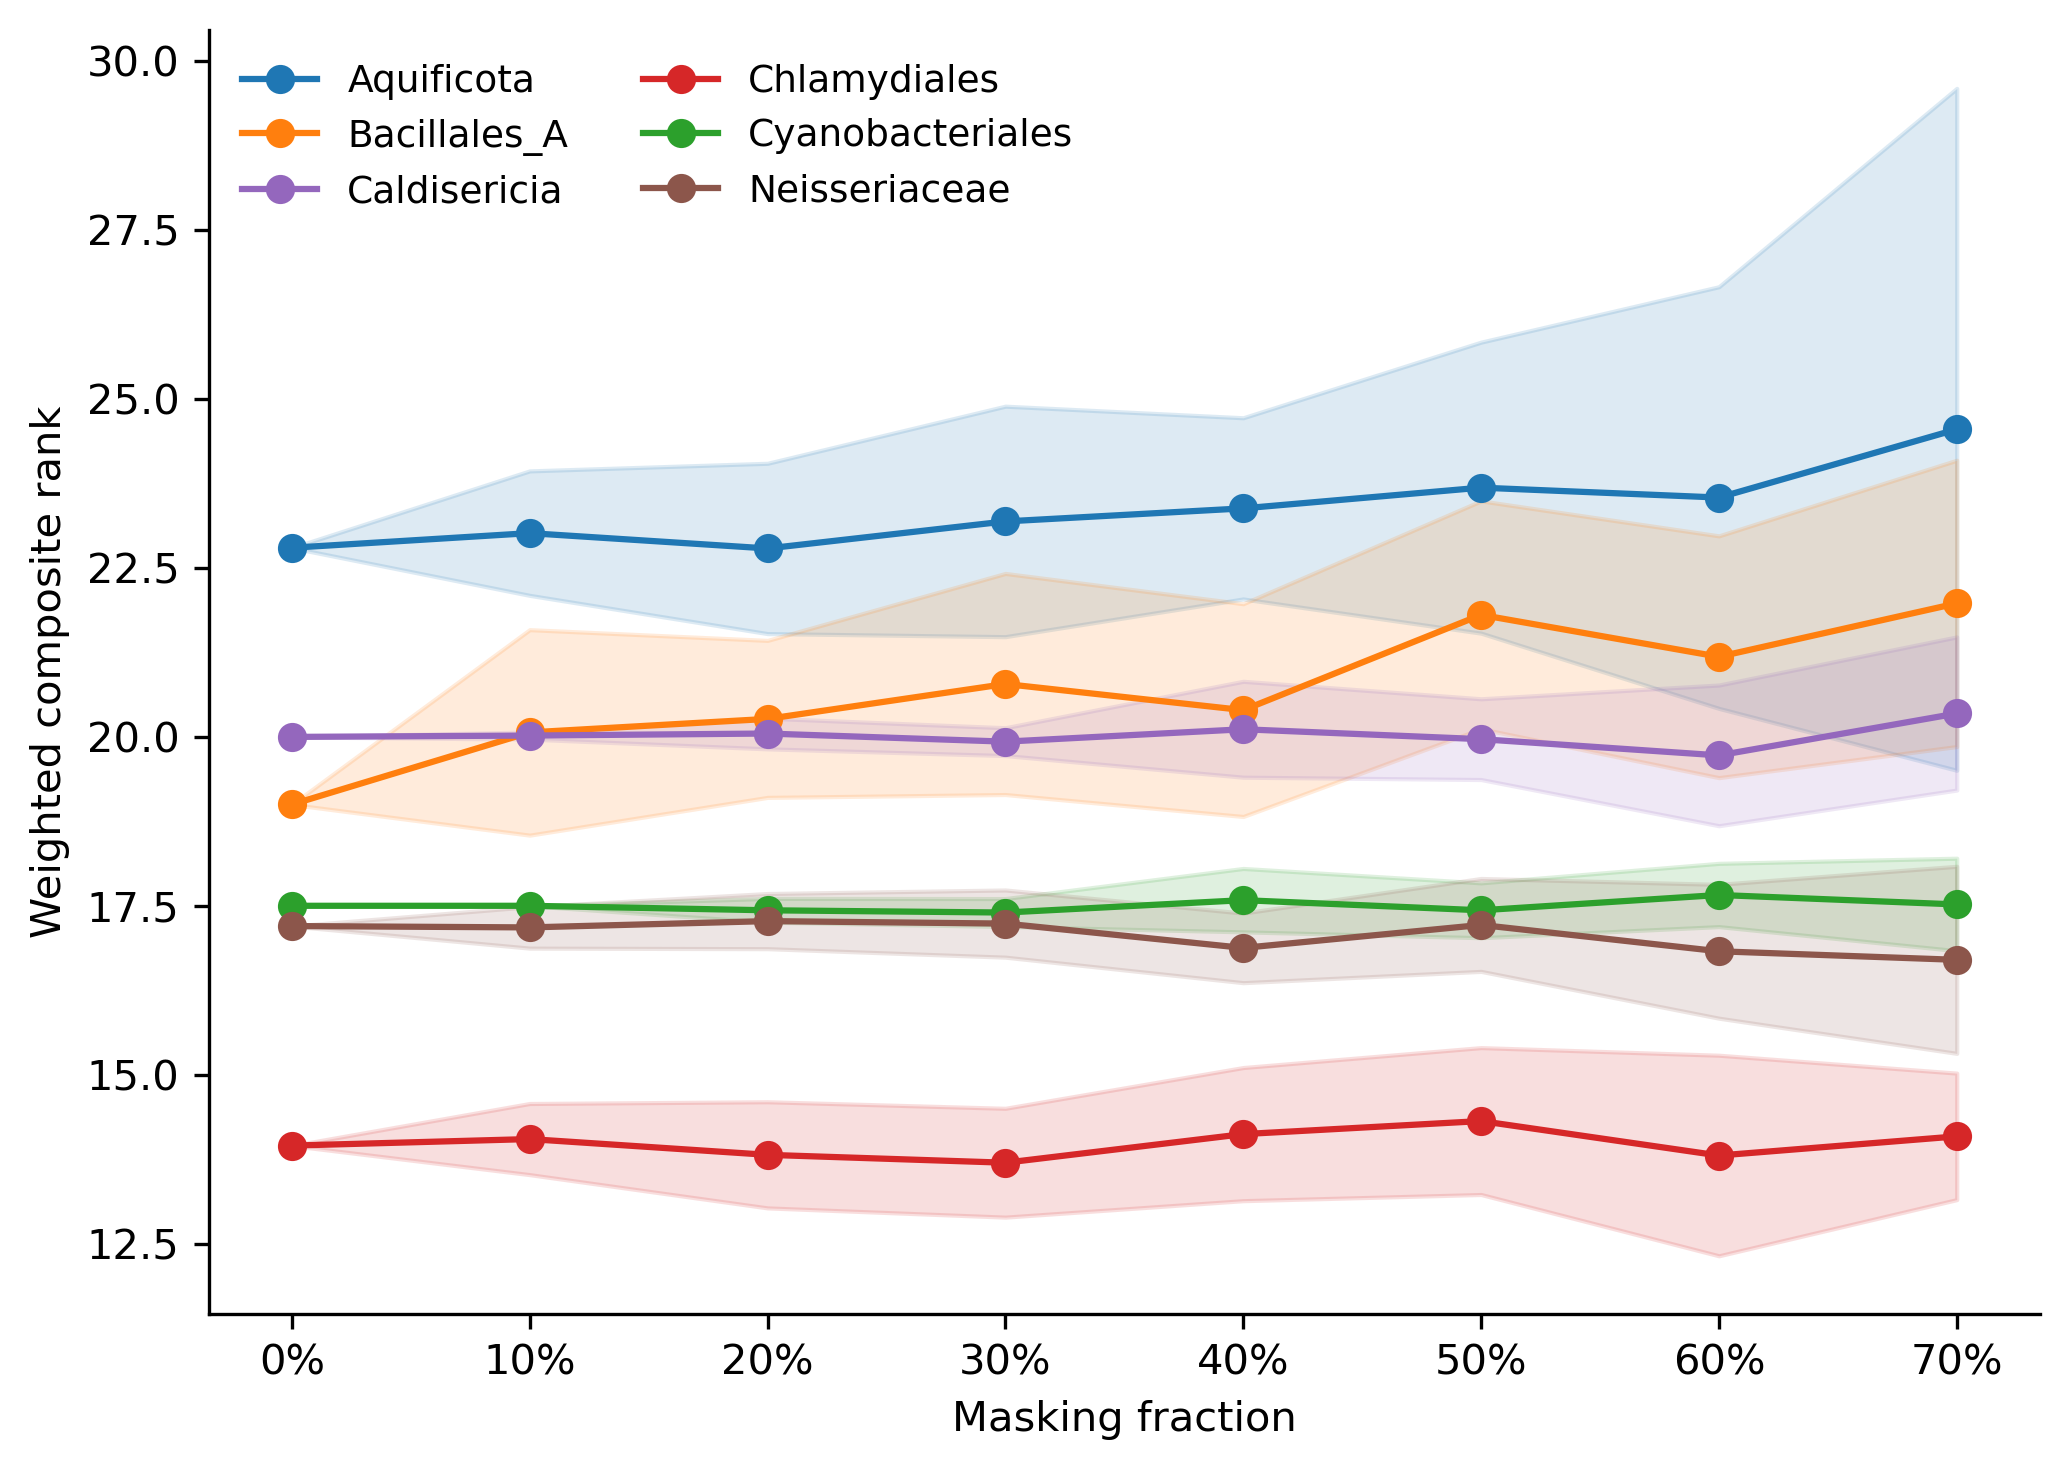

In [21]:
# new global consistency results, just plot masking fraction

from ete3 import Tree, TreeStyle, TextFace, NodeStyle, faces
import ok_k_mer_tree_mask as tm
importlib.reload(tm)


global_consistency_results = {}
for (name, merged_df), (tree_name, tree_path) in zip(merged_df_datasets, tree_datasets):
    print(name)
    tree = tm.load_named_tree(tree_path)
    # res = tm.global_effective_match_consistency(tree, merged_df, fracs=mask_fracs, n_runs=15, k_low=6, k_high=40, seed=0)
    res = tm.load_global_effective_match_results(f"res/{name}_global_eff_match.pkl")
    global_consistency_results[name] = res

# Effective length vs masking fraction, all datasets in one panel
plot = tm.plot_effective_length_vs_masking(global_consistency_results)

# Replot without re-running simulation:
# res = tm.load_global_effective_match_results("res/Bacillales_global_eff_match.pkl")
# tm.plot_global_effective_match_consistency(res, "Bacillales")

################################################################################
# original global consistency results:

##global_consistency_results = {}
#for (name, merged_df), (tree_name, tree_path) in zip(merged_df_datasets, tree_datasets):
#    print(name)
#    tree = tm.load_named_tree(tree_path)
#    res = tm.global_consistency(tree, merged_df, fracs=mask_fracs, n_runs=10,
#                                k_low=6, k_high=40, seed=0)
#    global_consistency_results[name] = res
#    tm.plot_global_consistency(res, name)
#    print()

In [ ]:
## Save Fig 4 (tree masking) for the manuscript
#figdir = "/scratch4/blangme2/sjhwang/ok_k_mer_manuscript/figures"
#os.makedirs(figdir, exist_ok=True)
#
#plot.savefig(
#    f"{figdir}/fig4_tree_masking.pdf",
#    format="pdf",
#    bbox_inches="tight",
#    pad_inches=0.03,
#    facecolor="white",
#)
#
## Archival raster copy at 600 dpi
#plot.savefig(
#    f"{figdir}/fig4_tree_masking_600dpi.png",
#    dpi=600,
#    bbox_inches="tight",
#    pad_inches=0.03,
#    facecolor="white",
#)

Aquificota


AttributeError: 'GlobalEffectiveMatchResults' object has no attribute 'groupby'

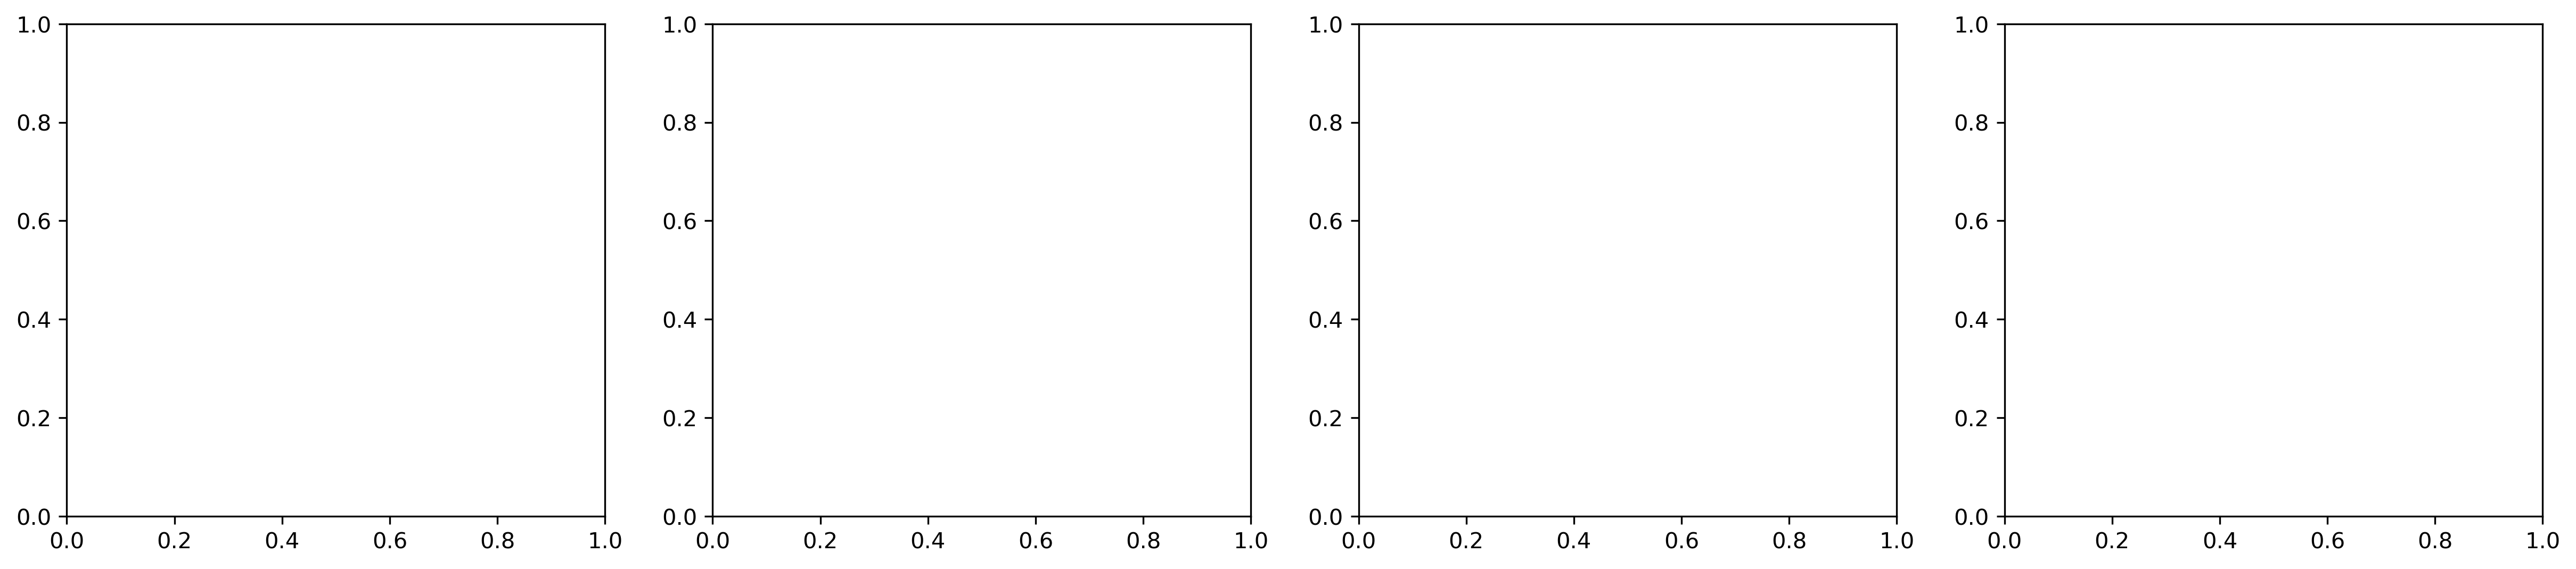

In [22]:
# original global consistency results:

global_consistency_results = {}
for (name, merged_df), (tree_name, tree_path) in zip(merged_df_datasets, tree_datasets):
    print(name)
    tree = tm.load_named_tree(tree_path)
    # res = tm.global_consistency(tree, merged_df, fracs=mask_fracs, n_runs=10, k_low=6, k_high=40, seed=0)
    res = tm.load_global_effective_match_results(f"res/{name}_global_eff_match.pkl")
    global_consistency_results[name] = res
    tm.plot_global_consistency(res, name)
    print()

## Per-node consistency vs masking fraction

Because masking preserves the tree topology, every internal node can be
compared directly to its full-data recommendation. We report the per-node
match rate (`k_eff` within +/-1 k) and the Kendall-tau distance of each
node's genome-pair ordering (full vs masked, and degradation vs truth).

In [ ]:
node_consistency_results = {}
for (name, merged_df), (tree_name, tree_path) in zip(merged_df_datasets, tree_datasets):
    print(name)
    tree = tm.load_named_tree(tree_path)
    res = tm.node_consistency(tree, merged_df, fracs=mask_fracs,
                              n_runs=5, k_low=6, k_high=40, seed=0)
    node_consistency_results[name] = res
    tm.plot_node_consistency(res, name)
    print()

## Within-tree correlations

Do a node's recommended k-mer length (`k_eff`) and number of k's relate to
where the node sits in the tree? For each internal node we correlate its
recommendation against its distance and depth from the root and its subtree
size (number of descendant leaves), reporting Spearman rho per panel.

In [ ]:
within_tree_corrs = {}
for (name, merged_df), (tree_name, tree_path) in zip(merged_df_datasets, tree_datasets):
    print(name)
    tree = tm.load_named_tree(tree_path)
    node_info = tm.compute_node_annotations(tree, merged_df, k_low=6, k_high=40)
    table = tm.node_recommendation_table(tree, node_info)
    within_tree_corrs[name] = tm.plot_within_tree_correlations(table, name)
    print()

# Scratch

In [ ]:
# Plot for ISMB presentation

# Load 1k grid-search tensor: columns are [k, |Spearman corr|, p-value]
chlamydia_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor_1k.npy'
chlamydia_grid = np.abs(np.load(chlamydia_grid_path))


################################################################################
k_low, k_high = 6, 32
mask = (chlamydia_grid[:, 0] >= k_low) & (chlamydia_grid[:, 0] <= k_high)
chlamydia_grid = chlamydia_grid[mask]

k_vals = chlamydia_grid[:, 0].astype(int)
corr_vals = chlamydia_grid[:, 1].astype(float)
best_k = int(k_vals[np.nanargmax(corr_vals)])

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(k_vals, corr_vals, marker="o", color="black", linewidth=0.8, markersize=4)
ax.axhline(0.513, color="red", ls="-.", linewidth=2)                                # comment for no red line
ax.set_xlabel("k-mer length", fontsize=16)
ax.set_ylabel("Spearman correlation", fontsize=16)
ax.set_ylim(0, 0.55)
ax.set_title("Jaccard Index: Chlamydiales", fontsize=20, loc="left")
ax.set_xticks(k_vals)
ax.set_xticklabels(k_vals, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
